In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import process_alignment

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']
cell_lines = list(cell_line_dict.values())

TEMPDIR = Path(config['TEMPDIR'])

# Which guides are truly transcript-specific?

Problem: 
We have guides that are supposedly targeting a specific transcript of a gene.
However, we find the same sequence of the guide in multiple transcripts, which is apparent:
- when we compare the results from annotating the guides against the genome or the transcriptome.
- when looking at the guide sequences suggested by Sanjana lab (they were overlapping between transcripts, so cannot be unique to a transcript).

Goal:
The goal is to identify the guides that are truly specific to a transcript.

Approach:
- We can check if the guide aligns to multiple transcripts. (do this)
- We could export all top guides from the Sanjana lab and check if they are unique to a transcript. (bad idea)

In [22]:
# Keep multiple alignments
tab_rna_45 = process_alignment(TEMPDIR / "pooled_screen_1/hisat2/guides_aligned_to_v45_transcriptome.sam", True)
tab_rna_19 = process_alignment(TEMPDIR / "pooled_screen_1/hisat2/guides_aligned_to_v19_transcriptome.sam", True)
tab_rna = pd.concat(dict(v45=tab_rna_45, v19=tab_rna_19), axis=0, names=['version']).reset_index(level=0, drop=False)
tab_dna = process_alignment(TEMPDIR / "pooled_screen_1/hisat2/guides_aligned_to_genome.sam", True)

# Annotate transcript alignment
tab_rna['alignment_transcriptID'] = tab_rna.chromosome.str.split('|').str[0].str.split('.').str[0]
tab_rna['alignment_on_target_transcript'] = tab_rna['alignment_transcriptID'] == tab_rna.Transcript_ID
tab_rna['alignment_gene'] = tab_rna.chromosome.str.split('|').str[5]
tab_rna['alignment_gene_id'] = tab_rna.chromosome.str.split('|').str[1].str.split('.').str[0]
tab_rna['alignment_on_target_gene'] = tab_rna['alignment_gene_id'] == tab_rna.ensembl_gene_id

# Annotate 2 (?)
tab_rna['GuideName_start'] = tab_rna.GuideName.str.split(':').str[1].str.split('-').str[0]
tab_rna['GuideName_end'] = tab_rna.GuideName.str.split(':').str[1].str.split('-').str[1]
tab_rna.GuideName_start = [int(x) if x == x else np.nan for x in tab_rna.GuideName_start]
tab_rna.GuideName_end = [int(x)+1 if x == x else np.nan for x in tab_rna.GuideName_end]
tab_rna['offset'] = tab_rna.GuideName_start - tab_rna.Start_position
tab_rna['alignment_type'] = ['None' if flag!=flag else 'primary' if flag <=16 else 'secondary' for flag in tab_rna.Flag]

# How many alignments are within the same gene and how many are in the same transcript?
tab_rna['alignment_site'] = 'different genes'
tab_rna['alignment_site'][tab_rna['alignment_transcriptID'].isna()] = 'no alignment'
tab_rna['alignment_site'][tab_rna['alignment_on_target_gene']] = 'same gene, different transcript'
tab_rna['alignment_site'][tab_rna['alignment_on_target_transcript']] = 'same transcript, different target site'
tab_rna['alignment_site'][np.abs(tab_rna['offset'])<=1] = 'same target site'
class_dict={
    'no alignment': -1,
    'different genes': 0, 
    'same gene, different transcript': 1, 
    'same transcript, different target site': 2, 
    'same target site': 3}
tab_rna['alignment_site_class'] = tab_rna['alignment_site'].map(class_dict)

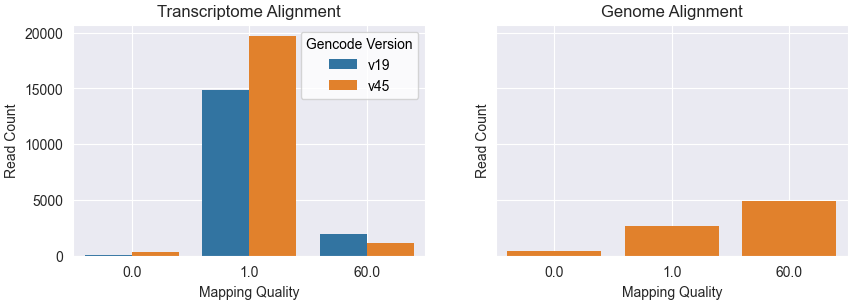

In [ ]:
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(5*2, 3), sharey=True)
ax = axs[0]
data = tab_rna.fillna(0).value_counts(['MappingQuality', 'version']).sort_index().reset_index()
sns.barplot(data=data, x='MappingQuality', y=0, hue='version', ax=ax)
ax.set_xlabel('Mapping Quality')
ax.set_ylabel('Read Count')
ax.set_title('Transcriptome Alignment')
ax.grid(True)
ax.legend(title='Gencode Version')

ax = axs[1]
data = tab_dna.fillna(0).value_counts('MappingQuality').sort_index().reset_index()
sns.barplot(data=data, x='MappingQuality', y=0, ax=ax, color='tab:orange')
ax.set_xlabel('Mapping Quality')
ax.set_ylabel('Read Count')
ax.set_title('Genome Alignment')
ax.grid(True)

pl.show()

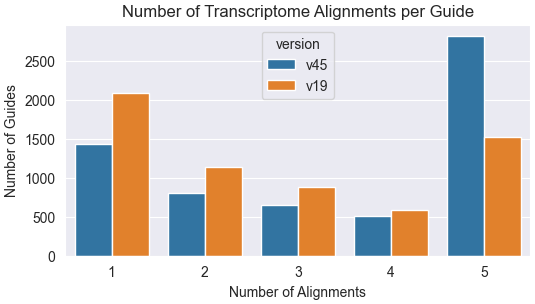

In [14]:
# How many guide have multiple alignments?
data = tab_rna.value_counts([tab_rna.index, 'version']).reset_index().rename({0: 'reads'}, axis=1).value_counts(['version', 'reads']).reset_index()

with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6, 3))
    sns.barplot(data=data, x='reads', y=0, hue='version', ax=ax)
pl.xlabel('Number of Alignments')
pl.ylabel('Number of Guides')
pl.title('Number of Transcriptome Alignments per Guide')
pl.show()

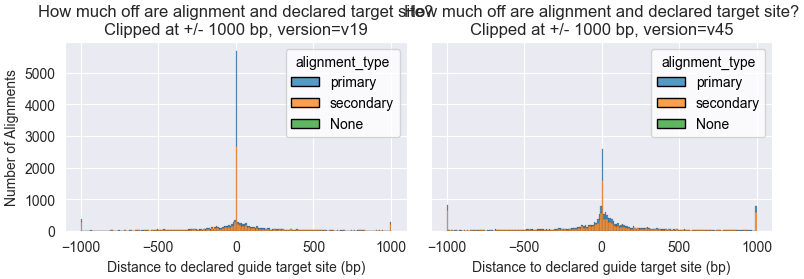

In [15]:
n_clip = 1000
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(8, 3), sharex=True, sharey=True)
for version, ax in zip(['v19', 'v45'], axs):
    df = tab_rna[tab_rna.version == version].copy()
    df.offset = df.offset.clip(-n_clip, n_clip)
    df.reset_index(inplace=True)
    sns.histplot(data=df, x='offset', bins=200, hue='alignment_type', multiple='stack', ax=ax)
    ax.set_title(f'How much off are alignment and declared target site?\nClipped at +/- {n_clip} bp, version={version}')
    ax.set_ylabel('Number of Alignments')
    ax.set_xlabel('Distance to declared guide target site (bp)')
pl.tight_layout()
pl.show()

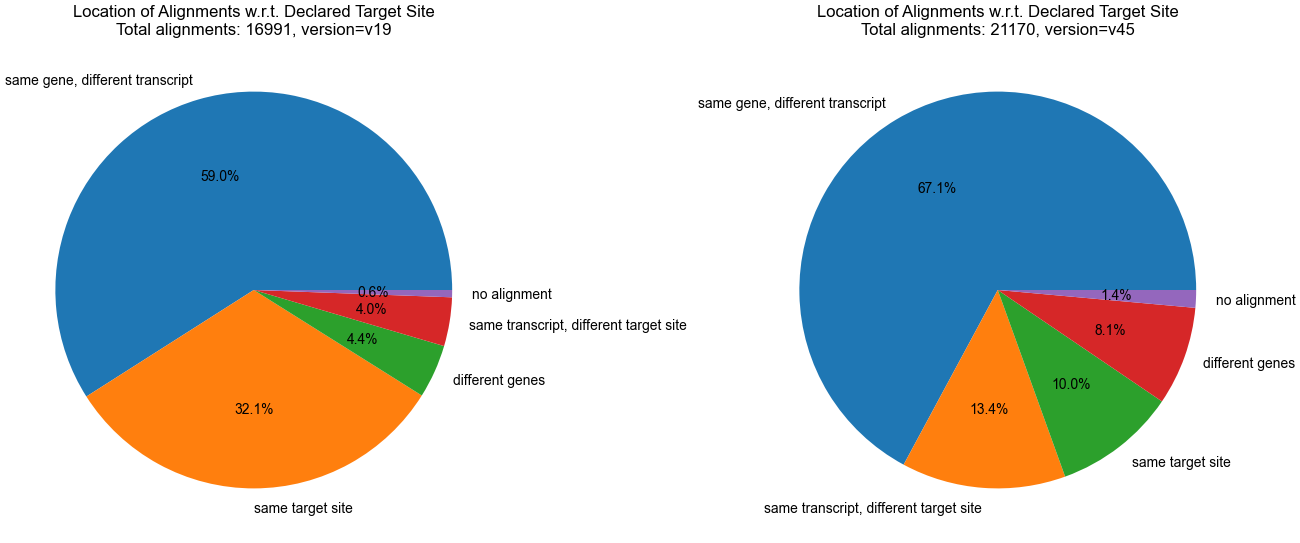

In [16]:
cts = tab_rna['alignment_site'].value_counts()
fig, axs = pl.subplots(1, 2, figsize=(16, 8), gridspec_kw={'wspace': 0.5})
for ax, version in zip(axs, ['v19', 'v45']):
    cts = tab_rna[tab_rna.version == version]['alignment_site'].value_counts()
    ax.pie(cts, labels=cts.index, autopct='%1.1f%%')
    ax.set_title(f'Location of Alignments w.r.t. Declared Target Site\nTotal alignments: {cts.sum()}, version={version}')
pl.show()

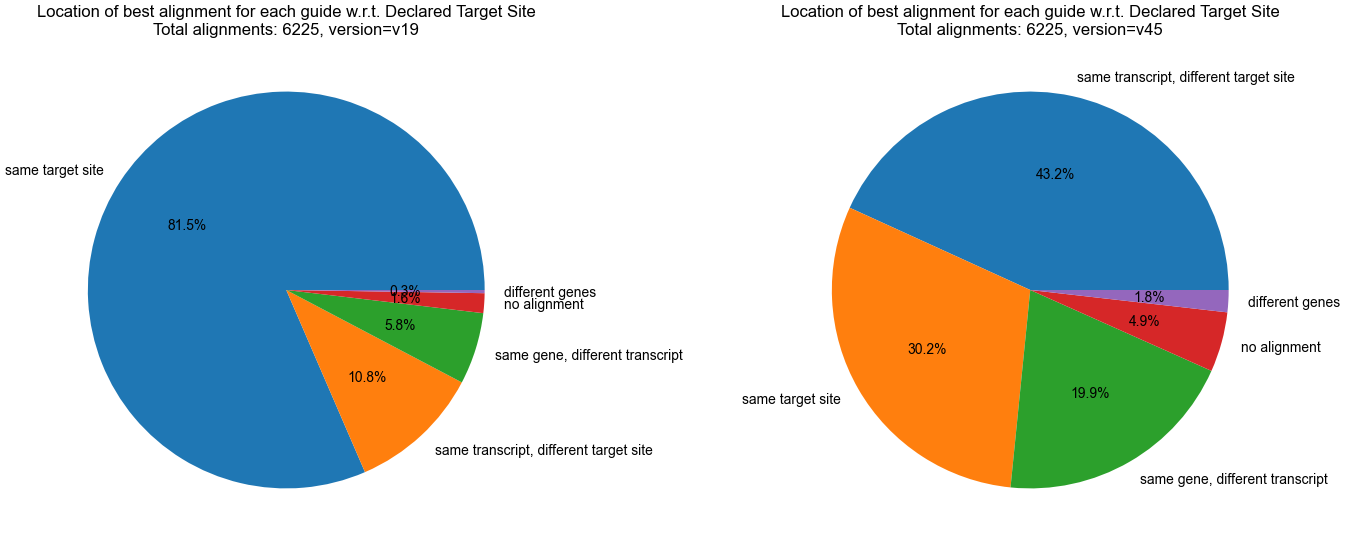

In [17]:
fig, axs = pl.subplots(1, 2, figsize=(16, 8), gridspec_kw={'wspace': 0.5})
flipped_class_dict = {v: k for k, v in class_dict.items()}
for ax, version in zip(axs, ['v19', 'v45']):
    best_class = tab_rna[tab_rna.version==version].reset_index().value_counts(['index', 'alignment_site_class'], sort=False).reset_index().drop(0, axis=1).groupby('index').max()
    best_class_label = best_class.alignment_site_class.map(flipped_class_dict)
    assert len(best_class_label) == 6225

    cts = best_class_label.value_counts()
    ax.pie(cts, labels=cts.index, autopct='%1.1f%%')
    ax.set_title(f'Location of best alignment for each guide w.r.t. Declared Target Site\nTotal alignments: {cts.sum()}, version={version}')
pl.show()

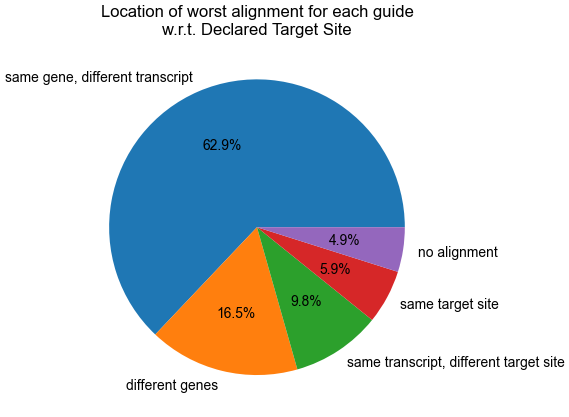

In [18]:
# Worst alignment for each guide
X = tab_rna.reset_index().value_counts(['index', 'alignment_site_class'], sort=False).unstack().fillna(0)
flipped_class_dict = {v: k for k, v in class_dict.items()}
best_class = tab_rna.reset_index().value_counts(['index', 'alignment_site_class'], sort=False).reset_index().drop(0, axis=1).groupby('index').min()
best_class_label = best_class.alignment_site_class.map(flipped_class_dict)
assert len(best_class_label) == 6225

cts = best_class_label.value_counts()
pl.pie(cts, labels=cts.index, autopct='%1.1f%%')
pl.title('Location of worst alignment for each guide\nw.r.t. Declared Target Site')
pl.show()

# Converting things to BED format for visualization

Things to convert:
- Guide positions (claimed)
- Guide positions (alignments)

In [19]:
class_dict

{'no alignment': -1,
 'different genes': 0,
 'same gene, different transcript': 1,
 'same transcript, different target site': 2,
 'same target site': 3}

In [47]:
tab_rna_sub = tab_rna[tab_rna.alignment_site_class.isin([1, 2, 3])].reset_index()

In [54]:
tab_rna_sub[tab_rna_sub.alignment_site_class == 1].alignment_gene.value_counts().head(10)

BIN1        195
PCBP4       184
GAS5        181
ZFAND6      174
SNHG15      172
CHCHD7      165
HOTAIRM1    165
RAN         160
MBD1        159
RAD51       145
Name: alignment_gene, dtype: int64

In [48]:
# convert to bed format
bed_df = tab_rna_sub[['chromosome', 'Start_position', 'End_position', 'index', 'strand']]
bed_df['score'] = 1000
bed_df.columns = ['chrom', 'start', 'end', 'name', 'strand', 'score']
bed_df = bed_df[['chrom', 'start', 'end', 'name', 'score', 'strand']]
bed_df.start = bed_df.start.astype(int).astype(str)
bed_df.end = bed_df.end.astype(int).astype(str)
bed_df = bed_df[bed_df.name.duplicated(keep=False)]  # take only multiple alignments
# Note: due to some bug I manually have to remove the trailing .0 from all numbers...
# I think this is because there are some None values in the start and end position columns
# https://stackoverflow.com/questions/56345170/prevent-trailing-zero-with-pandas-to-csv
bed_df.to_csv(TEMPDIR / 'pooled_screen_1/igv/alignments.bed', sep='\t', index=False, header=False)

In [46]:
# convert to bed format
bed_df = tab_dna.reset_index()[['chromosome', 'Start_position', 'End_position', 'index', 'strand']]
bed_df['score'] = 1000
bed_df.columns = ['chrom', 'start', 'end', 'name', 'strand', 'score']
bed_df = bed_df[['chrom', 'start', 'end', 'name', 'score', 'strand']]
bed_df = bed_df[~bed_df.start.isna().copy()]
bed_df.start = bed_df.start.astype(int).astype(str)
bed_df.end = bed_df.end.astype(int).astype(str)
bed_df.loc[bed_df.name.duplicated(keep=False), 'score'] = 500  # mark multiple alignments
# Note: due to some bug I manually have to remove the trailing .0 from all numbers...
# I think this is because there are some None values in the start and end position columns
# https://stackoverflow.com/questions/56345170/prevent-trailing-zero-with-pandas-to-csv
bed_df.to_csv(TEMPDIR / 'pooled_screen_1/igv/genome_alignments.bed', sep='\t', index=False, header=False)

# Classify transcript specificity

In [222]:
# Keep multiple alignments
tab_rna_45 = process_alignment(TEMPDIR / "pooled_screen_1/hisat2/guides_aligned_v45_transcriptome.sam", True)
tab_rna_19 = process_alignment(TEMPDIR / "pooled_screen_1/hisat2/guides_aligned_v19_transcriptome.sam", True)
tab_rna = pd.concat(dict(v45=tab_rna_45, v19=tab_rna_19), axis=0, names=['version']).reset_index(level=0, drop=False)

# Annotate transcript alignment
tab_rna['alignment_transcriptID'] = tab_rna.chromosome.str.split('|').str[0].str.split('.').str[0]
tab_rna['alignment_on_target_transcript'] = tab_rna['alignment_transcriptID'] == tab_rna.Transcript_ID
tab_rna['alignment_gene'] = tab_rna.chromosome.str.split('|').str[5]
tab_rna['alignment_gene_id'] = tab_rna.chromosome.str.split('|').str[1].str.split('.').str[0]
tab_rna['alignment_on_target_gene'] = tab_rna['alignment_gene_id'] == tab_rna.ensembl_gene_id

# Annotate 2 (?)
tab_rna['GuideName_start'] = tab_rna.GuideName.str.split(':').str[1].str.split('-').str[0]
tab_rna['GuideName_end'] = tab_rna.GuideName.str.split(':').str[1].str.split('-').str[1]
tab_rna.GuideName_start = [int(x) if x == x else np.nan for x in tab_rna.GuideName_start]
tab_rna.GuideName_end = [int(x)+1 if x == x else np.nan for x in tab_rna.GuideName_end]
tab_rna['offset'] = tab_rna.GuideName_start - tab_rna.Start_position
tab_rna['alignment_type'] = ['None' if flag!=flag else 'primary' if flag <=16 else 'secondary' for flag in tab_rna.Flag]

# How many alignments are within the same gene and how many are in the same transcript?
tab_rna['alignment_site'] = 'different genes'
tab_rna['alignment_site'][tab_rna['alignment_transcriptID'].isna()] = 'no alignment'
tab_rna['alignment_site'][tab_rna['alignment_on_target_gene']] = 'same gene, different transcript'
tab_rna['alignment_site'][tab_rna['alignment_on_target_transcript']] = 'same transcript, different target site'
tab_rna['alignment_site'][np.abs(tab_rna['offset'])<=1] = 'same target site'
class_dict={
    'no alignment': -1,
    'different genes': 0, 
    'same gene, different transcript': 1, 
    'same transcript, different target site': 2, 
    'same target site': 3}
tab_rna['alignment_site_class'] = tab_rna['alignment_site'].map(class_dict)

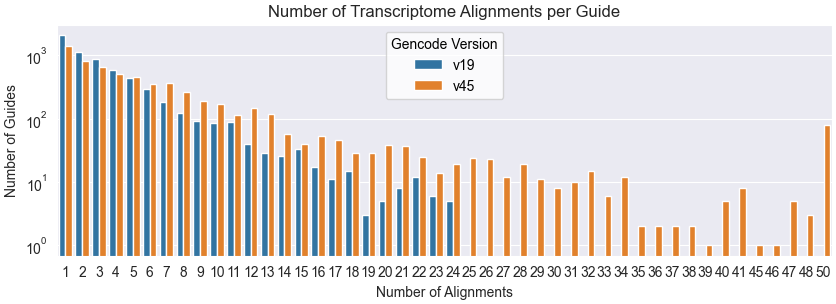

In [223]:
# How many guide have multiple alignments?
data = tab_rna.value_counts([tab_rna.index, 'version']).reset_index().rename({0: 'reads'}, axis=1).value_counts(['version', 'reads']).reset_index()

with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(10, 3))
    sns.barplot(data=data, x='reads', y=0, hue='version', ax=ax)
pl.xlabel('Number of Alignments')
pl.ylabel('Number of Guides')
pl.yscale('log')
pl.legend(title='Gencode Version')
pl.title(f'Number of Transcriptome Alignments per Guide')
pl.show()

In [273]:
from itertools import groupby

def fasta_iter(fasta_name):
    """
    modified from Brent Pedersen
    https://www.biostars.org/p/710/
    given a fasta file. yield tuples of header, sequence
    """
    "first open the file outside "
    fh = open(fasta_name)

    # ditch the boolean (x[0]) and just keep the header or sequence since
    # we know they alternate.
    faiter = (x[1] for x in groupby(fh, lambda line: line[0] == ">"))

    for header in faiter:
        # drop the ">"
        headerStr = header.__next__()[1:].strip()

        # join all sequence lines to one.
        seq = "".join(s.strip() for s in faiter.__next__())

        yield (headerStr, seq)


In [304]:
version = 'v19'
# version = 'v45'

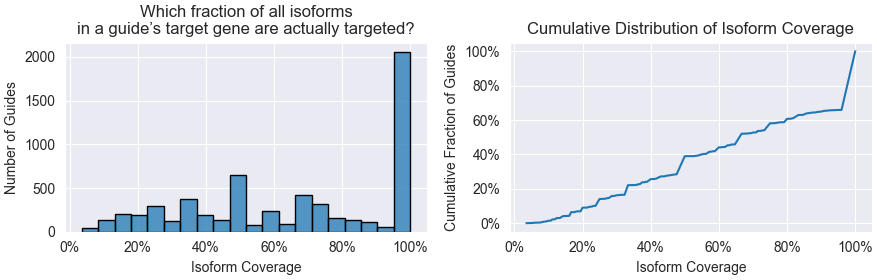

In [305]:
fiter = fasta_iter(f'/scratch/peidli/SYMPHONY/pooled_screen_1/hisat2/gencode.{version}.transcripts.fa')
headers = list()
for ff in fiter:
    headers.append(ff[0].split('|')[:6])
fasta = pd.DataFrame(headers, columns=['transcript_id', 'gene_id', 'A', 'B', 'transcript_symbol', 'gene_symbol'])

guide_tab = pd.DataFrame(index=tab_rna.index.unique())
tab_rna_ = tab_rna[tab_rna.version == version].copy()

# list of aligned isoforms on target gene per guide
guide_tab['targeted_transcripts'] = tab_rna_[tab_rna_.alignment_on_target_gene].alignment_transcriptID.reset_index().groupby('index').apply(lambda x: x.alignment_transcriptID.tolist())

# Number of isoforms in target gene
number_of_transcripts = fasta.groupby('gene_id').transcript_id.count()
number_of_transcripts.index = number_of_transcripts.index.str.split('.').str[0]
guide_tab['declared_target_geneID'] = tab_rna_.loc[guide_tab.index, 'ensembl_gene_id'].reset_index().groupby('index').apply(lambda x: pd.unique(x.ensembl_gene_id.tolist())[0])  # I checked, there is only one gene per guide as declared target (sanity check)
guide_tab['declared_target_transcriptID'] = tab_rna_.loc[guide_tab.index, 'Transcript_ID'].reset_index().groupby('index').apply(lambda x: pd.unique(x.Transcript_ID.tolist())[0])  # I checked, there is only one gene per guide as declared target (sanity check)
guide_tab['number_of_isoforms_of_target_gene'] = [number_of_transcripts.loc[x] if x in number_of_transcripts.index else None for x in guide_tab.declared_target_geneID]

# Coverage
guide_tab['number_of_aligned_isoforms'] = [len(x) if x==x else None for x in guide_tab.targeted_transcripts]
guide_tab['isoform_coverage'] = guide_tab.number_of_aligned_isoforms / guide_tab.number_of_isoforms_of_target_gene
guide_tab['isoform_coverage'][guide_tab['isoform_coverage'] > 1] = None  # there is a single occurrence of 7, which is weird

# Hit
guide_tab['declared_target_in_actual_targets'] = [np.isin(x, y) if x==x and y==y else None for x, y in zip(guide_tab.declared_target_transcriptID, guide_tab.targeted_transcripts)]

data = guide_tab.isoform_coverage.value_counts().reset_index().sort_values('index', ascending=True)
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(4.5*2, 3))
ax = axs[0]
sns.histplot(data=guide_tab, x='isoform_coverage', bins=20, ax=ax)
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel('Isoform Coverage')
ax.set_ylabel('Number of Guides')
# pl.yscale('log')
ax.set_title("Which fraction of all isoforms\nin a guide’s target gene are actually targeted?")

# Plot cumulative distribution
data['cumulative'] = data.isoform_coverage.cumsum() / data.isoform_coverage.sum()
ax = axs[1]
sns.lineplot(data=data, x='index', y='cumulative', ax=ax)
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel('Isoform Coverage')
ax.set_ylabel('Cumulative Fraction of Guides')
ax.set_title("Cumulative Distribution of Isoform Coverage")
pl.tight_layout()
pl.savefig(f'../results/figures/SYM101_transcript_isoform_coverage_{version}.pdf')
pl.show()

In [ ]:
guide_tab.to_csv(f'../results/tables/SYM101_transcript_isoform_coverage_{version}.csv')

# Expression-weighted coverage

## Prepare expression

In [294]:
# wget https://plus.figshare.com/ndownloader/files/46493506 -O OmicsExpressionTranscriptsTPMLogp1Profile.csv
# wget https://plus.figshare.com/ndownloader/files/46489732 -O Model.csv
# wget https://plus.figshare.com/ndownloader/files/46500358 -O OmicsProfiles.csv

In [2]:
version = 'v19'
guide_tab = pd.read_csv(f'../results/tables/SYM101_transcript_isoform_coverage_{version}.csv', index_col=0)

In [3]:
# takes really long, is only 3 GB in size
depmap_expression_ = pd.read_csv("/scratch/peidli/DepMap/Release_2024Q2/OmicsExpressionTranscriptsTPMLogp1Profile.csv", index_col=0, usecols=[0])
# For mapping expression row indices to cell lines
depmap_models = pd.read_csv("/scratch/peidli/DepMap/Release_2024Q2/Model.csv", index_col=0)
idx = depmap_models[depmap_models.CellLineName.isin(['NCI-H1299', 'NCI-H1975', 'A549'])].index  # order is also preserved here
# idx = ['ACH-000510', 'ACH-000587', 'ACH-000681']

In [50]:
depmap_omics_models = pd.read_csv("/scratch/peidli/DepMap/Release_2024Q2/OmicsProfiles.csv", index_col=2)
profiles = depmap_omics_models.loc[idx].ProfileID
profiles = depmap_omics_models[depmap_omics_models.Datatype=='rna'].loc[idx,'ProfileID']
assert len(profiles) == 3
row_ids = np.where(depmap_expression_.index.isin(profiles.values))[0]  # idx of the cell lines in the expression matrix
assert len(row_ids) == 3
profiles

ModelID
ACH-000510    PR-Er9ReY
ACH-000587    PR-dmYRK0
ACH-000681    PR-Em6pVT
Name: ProfileID, dtype: object

In [56]:
# # get length of file
# with open('/scratch/peidli/DepMap/Release_2024Q2/OmicsExpressionTranscriptsTPMLogp1Profile.csv', "r") as f:
#     num_lines = sum(1 for _ in f)
num_lines = 1535

# read only data for selected cell lines (30sec)
to_exclude = [i for i in np.arange(num_lines) if (i-1 not in row_ids) and (i != 0)]
depmap_expression = pd.read_csv("/scratch/peidli/DepMap/Release_2024Q2/OmicsExpressionTranscriptsTPMLogp1Profile.csv", index_col=0, skiprows = to_exclude)

flip_idx_mapping = {v: k for k, v in profiles.to_dict().items()}
depmap_expression.index = depmap_expression.index.map(flip_idx_mapping)
ach_to_names = {
    'ACH-000587': 'H1975',
    'ACH-000681': 'A549',
    'ACH-000510': 'H1299'}
depmap_expression.index = depmap_expression.index.map(ach_to_names)

In [70]:
depmap_expression.to_csv(f'../results/tables/sym101_depmap_transcript_expression.csv')

## Analysis

In [1]:
depmap_expression = pd.read_csv(f'../results/tables/sym101_depmap_transcript_expression.csv', index_col=0).T
depmap_expression['Gene'] = depmap_expression.index.str.split(' (', regex=False).str[0]
depmap_expression['transcript_id'] = depmap_expression.index.str.split(' (', regex=False).str[-1].str.split(')', regex=False).str[0]
depmap_expression.set_index('transcript_id', inplace=True)

NameError: name 'pd' is not defined

In [80]:
version = 'v19'
cov = pd.read_csv(f'../results/tables/SYM101_transcript_isoform_coverage_{version}.csv', index_col=0)
lists = [eval(x) if x==x else [] for x in cov.targeted_transcripts.values]
# get union of list of lists of strings
union = set().union(*lists)
whitelist = list(union.intersection(depmap_expression.index))  # transcript ids that are in the expression matrix

In [169]:
# weighted coverage of a guide is defined by the sum of the isoform coverage of all isoforms of the target gene weighted by the expression of the isoforms in a cell line
for cell_line in ['H1299', 'H1975', 'A549']:
    print(cell_line)
    guide_tab[f'gex_of_aligned_isoforms_{cell_line}'] = [depmap_expression.loc[np.intersect1d(x, whitelist), cell_line].sum() if x==x else None for x in lists]
    guide_tab['target_gene_symbol'] = guide_tab.index.str.split('_').str[0]
    depmap_gex = depmap_expression.groupby('Gene').sum()
    guide_tab[f'total_gex_of_isoforms_of_target_gene_{cell_line}'] = [depmap_gex.loc[x, cell_line] if x in depmap_gex.index else None for x in guide_tab['target_gene_symbol']]

    # isoform_coverage: guide_tab.gex_of_aligned_isoforms / guide_tab.total_gex_of_isoforms_of_target_gene
    guide_tab[f'expression_weighted_isoform_coverage_{cell_line}'] = guide_tab[f'gex_of_aligned_isoforms_{cell_line}'] / guide_tab[f'total_gex_of_isoforms_of_target_gene_{cell_line}']
    guide_tab[f'expression_weighted_isoform_coverage_{cell_line}'] = guide_tab[f'expression_weighted_isoform_coverage_{cell_line}'].clip(0, 1)

H1299
H1975
A549


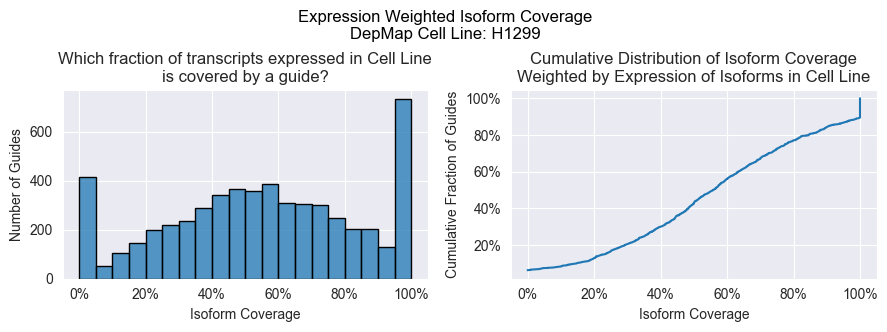

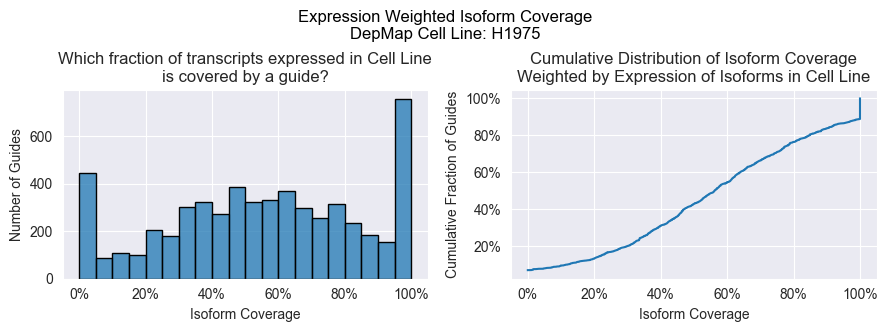

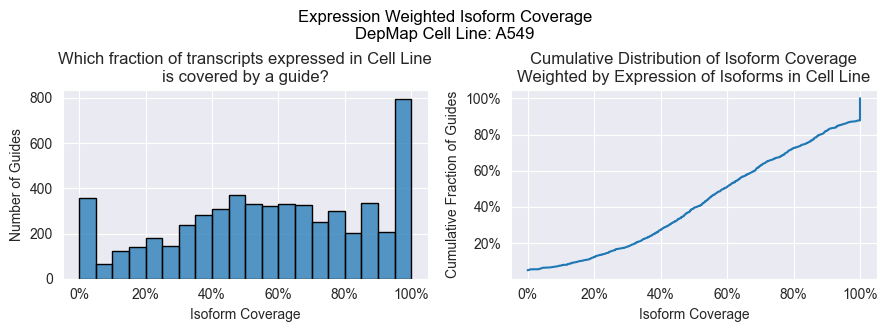

In [170]:
for cell_line in ['H1299', 'H1975', 'A549']:
    key = f'expression_weighted_isoform_coverage_{cell_line}'

    data = guide_tab[key].value_counts().reset_index().sort_values('index', ascending=True)
    with sns.axes_style('darkgrid'):
        fig, axs = pl.subplots(1, 2, figsize=(4.5*2, 3))
    ax = axs[0]
    sns.histplot(data=guide_tab, x=key, bins=20, ax=ax)
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
    ax.set_xlabel('Isoform Coverage')
    ax.set_ylabel('Number of Guides')
    # pl.yscale('log')
    ax.set_title("Which fraction of transcripts expressed in Cell Line\nis covered by a guide?")

    # Plot cumulative distribution
    data['cumulative'] = data[key].cumsum() / data[key].sum()
    ax = axs[1]
    sns.lineplot(data=data, x='index', y='cumulative', ax=ax)
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
    ax.set_xlabel('Isoform Coverage')
    ax.set_ylabel('Cumulative Fraction of Guides')
    ax.set_title("Cumulative Distribution of Isoform Coverage\nWeighted by Expression of Isoforms in Cell Line")
    pl.tight_layout()
    pl.suptitle(f"Expression Weighted Isoform Coverage\nDepMap Cell Line: {cell_line}", y=1.09)
    pl.savefig(f'../results/figures/SYM101_transcript_isoform_coverage_{version}_weighted_{cell_line}.pdf')
    pl.show()

# Outlier detection (deprecated because of the aforementioned issues)

In [ ]:
# Find genes where transcripts showed different reactions
# Can't use BAGEL for this. Will work on L2FC instead.
# Restrict to protein-coding region
sdf = df[df.Region=='CDS'].copy()
multi_transcript_genes = [gene for gene in sdf.Gene.unique() if len(sdf[sdf.Gene == gene].Transcript_ID.unique()) > 1]

In [ ]:
filter = pd.read_csv('../results/tables/pooled_screen_1_mageck_filtered_guides_v1.tsv', sep='\t', header=[0,1,2], index_col=0).droplevel(2, axis=1)
is_working = filter.loc[:, ('summary', 'is_working')]
# sdf = sdf.loc[is_working.index]

In [ ]:
sdf = sdf[sdf.Gene.isin(multi_transcript_genes)]
L = l2fc.loc[sdf.index, sample_names_wo_pools]

In [ ]:
L

,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,sym-01-01-TP6,sym-01-02-TP1,sym-01-02-TP2,sym-01-02-TP3,sym-01-02-TP4,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
ANAPC11_ENST00000344877_202,0.412015,0.369900,0.536509,0.580091,0.308489,-0.108070,0.242893,0.290519,0.045819,-0.035401,...,0.212249,0.095490,0.172924,0.037166,0.216169,0.261061,0.158150,0.190354,-0.155788,-0.109976
ANAPC11_ENST00000344877_204,0.474597,0.362447,0.335433,0.136449,0.027478,0.301345,0.364665,0.317609,0.363202,0.278205,...,0.075000,-0.045905,-0.075150,0.044423,0.294426,0.167683,0.261667,-0.012816,0.102772,0.103529
ANAPC11_ENST00000344877_374,0.201372,-0.037688,-0.050779,-0.031956,0.060283,0.085101,0.001154,-0.054299,0.034638,0.098147,...,0.147123,0.036241,-0.043348,0.008732,0.101639,0.153108,0.074120,0.077000,-0.100733,0.062741
ANAPC11_ENST00000579978_232,0.214941,-0.150430,0.076992,0.081761,0.185460,-0.138536,-0.194746,-0.123923,-0.226552,-0.254744,...,-0.045684,-0.226075,-0.273500,-0.228488,-0.013864,-0.029551,-0.081301,-0.256966,-0.244536,-0.255292
ANAPC11_ENST00000579978_233,-0.110474,0.181127,0.244365,0.283041,0.177209,0.147443,0.198662,0.169761,0.305489,0.171650,...,-0.006661,0.101077,0.130046,0.035998,-0.077720,-0.000240,-0.115191,0.107115,-0.064436,-0.200174
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2_ENST00000370920_541,0.233212,-0.014063,-0.894476,-1.445218,-1.808668,-2.502527,0.023167,-0.303353,-1.184761,-1.396507,...,-0.378122,-0.424553,-0.225600,-0.405982,0.172480,-0.206880,-0.214627,-0.429636,-0.404641,-0.540435
ZRANB2_ENST00000370920_738,0.108466,0.161241,0.244252,0.268561,0.125397,-0.177507,0.038689,-0.058115,-0.092975,-0.090920,...,-0.086082,-0.071181,-0.067710,-0.072547,0.072926,-0.067302,0.248733,-0.070964,-0.018676,0.085130
FBL_ENST00000597224_524,-0.613396,-2.965704,-6.943970,NaN,NaN,-9.709505,-1.496899,-3.964667,-7.497011,-6.704697,...,-2.179622,-2.726729,-2.476917,-2.966255,-0.037557,-1.469564,-2.157222,-3.057713,-3.221471,-3.252916


In [ ]:
L['Gene'] = sdf.Gene.copy()
L['Transcript_ID'] = sdf.Transcript_ID.copy()
mL = L.groupby(['Gene', 'Transcript_ID']).mean()
mmL = mL.mean(axis=1).to_frame().sort_values(0, ascending=False)
# annotate the Transcript_ID number of each gene
mmL['Transcript_ID_number'] = mmL.groupby('Gene').cumcount()+1
mmL.set_index('Transcript_ID_number', append=True, inplace=True)
mmL = mmL.reset_index()

In [ ]:
mmL

,Gene,Transcript_ID,Transcript_ID_number,0
0,MBD1,ENST00000347968,1,0.340078
1,PCBP4,ENST00000355852,1,0.309204
2,STARD8,ENST00000374597,1,0.253109
3,ATP5F1D,ENST00000215375,1,0.234240
4,PCBP4,ENST00000471622,2,0.218523
...,...,...,...,...
176,PPIA,ENST00000355968,2,-2.614012
177,UBE2I,ENST00000403747,2,-2.647368
178,RNPS1,ENST00000320225,2,-2.655010
179,NUTF2,ENST00000569436,2,-3.367088


In [ ]:
# now make a scatterplot where x is number 1 and y is number 2
# first need to pivot the table
pmmL = mmL.pivot(index='Gene', columns='Transcript_ID_number', values=0)

pmmL['min_l2fc'] = pmmL.min(axis=1, skipna=True)
pmmL['max_l2fc'] = pmmL.max(axis=1, skipna=True)

In [ ]:
pmmL

Transcript_ID_number,1,2,3,4,min_l2fc,max_l2fc
Gene,,,,,,
ANAPC11,-0.096340,-0.124690,NaN,NaN,-0.124690,-0.096340
ANAPC5,-0.538551,-1.244899,NaN,NaN,-1.244899,-0.538551
ATP5F1D,0.234240,-0.057472,NaN,NaN,-0.057472,0.234240
ATRAID,0.091821,0.009516,NaN,NaN,0.009516,0.091821
ATXN7L3,-0.031660,-0.077083,NaN,NaN,-0.077083,-0.031660
...,...,...,...,...,...,...
VARS2,-0.062155,-0.107240,NaN,NaN,-0.107240,-0.062155
WWP1,-0.186620,-0.859499,NaN,NaN,-0.859499,-0.186620
ZFAND6,0.140269,0.128588,-0.005544,NaN,-0.005544,0.140269


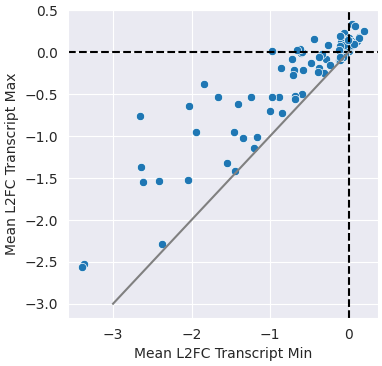

In [ ]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(4,4))
sns.scatterplot(data=pmmL, x='min_l2fc', y='max_l2fc', ax=ax)
pl.xlabel('Mean L2FC Transcript Min')
pl.ylabel('Mean L2FC Transcript Max')
pl.axhline(0, color='k', linestyle='--')
pl.axvline(0, color='k', linestyle='--')
# draw diagonal
pl.plot([-3, 0], [-3, 0], 'grey')
pl.show()

In [ ]:
hits = (pmmL.max_l2fc - pmmL.min_l2fc).sort_values(ascending=False).index[:10]
dat = mL.loc[hits]

<Axes: ylabel='Gene-Transcript_ID'>

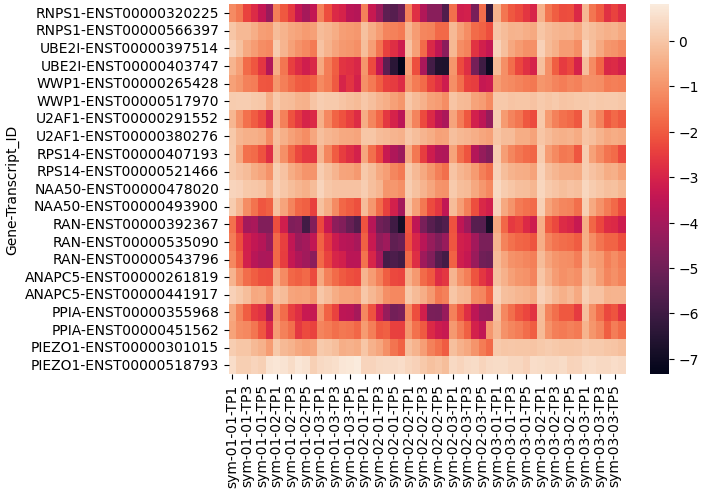

In [ ]:
sns.heatmap(dat)

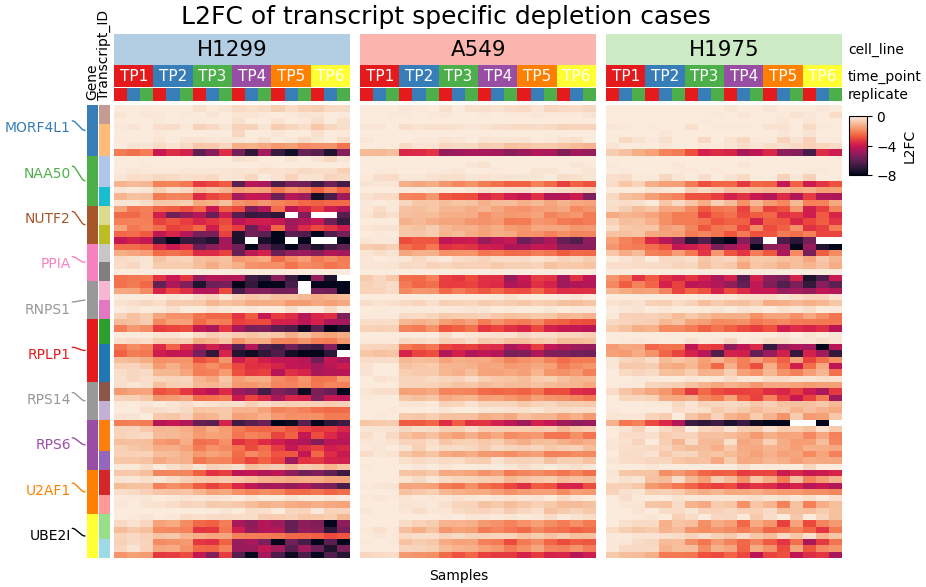

In [ ]:
# correlation between samples
cell_line = pd.Series({x: int(x.split('-')[1]) for x in sample_names_wo_pools}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names_wo_pools})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names_wo_pools})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

data = l2fc.loc[df.Gene.isin(hits) & (df.Region == 'CDS'), col_order].sort_index()

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=5, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df.loc[data.index, 'Gene'], merge=True, extend=True),
    Gene=pch.anno_simple(df.loc[data.index, 'Gene']),
    Transcript_ID=pch.anno_simple(df.loc[data.index, 'Transcript_ID']),
    verbose=0, axis=0, plot_legend=False
)

pl.figure(figsize=(10, 6))
cm = pch.ClusterMapPlotter(
    data=data, top_annotation=top_ha, left_annotation=left_ha,
    row_cluster=False, col_cluster=False,
    legend_gap=7, vmax=0, vmin=-8,
    col_split=cell_line.loc[col_order], col_split_gap=2.5,
    rasterized=True, cmap='rocket',
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='', legend_hpad=0,
    verbose=0
)
pl.suptitle("L2FC of transcript specific depletion cases", y=0.93, fontsize=18)
pl.savefig('../results/figures/l2fc_transcript_specific_depletion_heatmap.pdf', dpi=300, bbox_inches='tight')
pl.show()